# LAB 4 — PHẦN D: PROSODY & SOURCE–FILTER

**Môn học:** CSE457 — Xử lý âm thanh và tiếng nói.  
**Phạm vi:** Lab 4, mục 3.3–3.4, mục 4.4 (D), thí nghiệm 3–4 trong mục 6.  
**Đầu vào:** `audio_output/best_concat.wav` (phần C), `lab4_data/units/ba_01.wav` (phần A).  
**Mục tiêu:** đo F0 của một âm hữu thanh, kiểm chứng $F_0\approx F_s/N_p$, so sánh thay tốc độ nói **không đổi pitch** với pitch-shift **không chủ ý đổi formant**, trực quan hóa source–filter.

> Giữ nguyên `raw_concat.wav` và `best_concat.wav`. Các audio tạo ở bước D có tiền tố `d_`. **Không được coi source–filter mô phỏng là HMM-based TTS** (phần E là phần riêng).

## 0. Cấu trúc thư mục & cài thư viện

```text
Lab04_TTS/
├── Lab04_Buoc3_C.ipynb
├── Lab04_Buoc4_D.ipynb         ← notebook này
├── lab4_data/
│   └── units/
│       ├── ba_01.wav
│       └── ...
├── audio_output/
│   ├── raw_concat.wav
│   ├── best_concat.wav         ← đã tạo ở bước C
│   └── d_*.wav                ← sẽ sinh ở bước D
└── figures/
    └── d_*.png
```

VS Code → Open Folder `Lab04_TTS`, chọn Python Kernel đã chạy Lab 4A–C. Nếu thiếu gói:

```powershell
python -m pip install numpy scipy pandas matplotlib soundfile librosa ipython
```

**Chú ý:** Khi mở notebook, Current Working Directory phải là thư mục gốc `Lab04_TTS`, không phải `/mnt/data` hay thư mục `audio_output`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import librosa
from scipy.signal import correlate, lfilter, freqz, stft
from IPython.display import display, Audio

SR = 16000
ROOT = Path.cwd().resolve()
UNIT_DIR = ROOT / 'lab4_data' / 'units'
OUT_DIR = ROOT / 'audio_output'
FIG_DIR = ROOT / 'figures'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

INPUT_BEST = OUT_DIR / 'best_concat.wav'
INPUT_RAW = OUT_DIR / 'raw_concat.wav'
if not INPUT_BEST.exists():
    raise FileNotFoundError(f'Thiếu {INPUT_BEST}. Hãy chạy Lab04_Buoc3_C.ipynb trước.')

def read_wav(path):
    data, sr = sf.read(path, dtype='float32')
    if sr != SR or data.ndim != 1:
        raise ValueError(f'{path} phải là WAV 16 kHz mono, nhận {sr} Hz, ndim={data.ndim}')
    if not np.isfinite(data).all():
        raise ValueError(f'File có NaN/Inf: {path}')
    return data

def rms(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.sqrt(np.mean(x*x))) if len(x) else 0.0

best = read_wav(INPUT_BEST)
raw = read_wav(INPUT_RAW) if INPUT_RAW.exists() else None
print('ROOT:', ROOT)
print('Best concat:', len(best)/SR, 's | RMS:', round(rms(best),5), '| peak:',round(float(np.max(np.abs(best))),4))
print('Raw concat:', 'chưa có' if raw is None else f'{len(raw)/SR:.3f}s')

ROOT: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien
Best concat: 4.88 s | RMS: 0.0809 | peak: 0.6331
Raw concat: 5.000s


## 1. Chọn một unit hữu thanh để phân tích F0

Ưu tiên `ba_01.wav` vì nguyên âm **a** là đoạn hữu thanh dễ thấy tính tuần hoàn. Nếu thiếu file riêng lẻ, notebook trích đúng đoạn `ba` từ `raw_concat.wav` bằng mốc từ `baseline_boundary_diagnostics.csv` của bước B (không dùng audio giả).

F0 **chỉ có ý nghĩa tại frame hữu thanh**. Đối với silence và phụ âm vô thanh, không ép gán F0 = 0 Hz; dùng NaN để biểu diễn không phát hiện pitch.

c:\Users\admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Nguồn: lab4_data\units\ba_01.wav
Unit trước trim 0.500s; sau trim 0.360s; khoảng được giữ [2176, 7936] samples
RMS unit: 0.09426


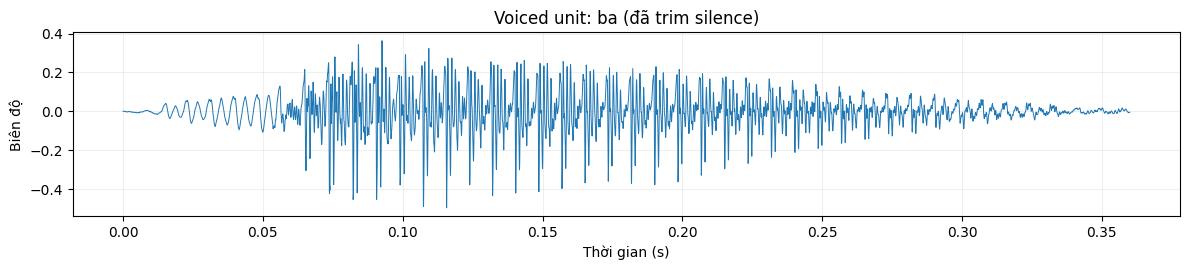

In [2]:
unit_path = UNIT_DIR / 'ba_01.wav'
if unit_path.exists():
    unit = read_wav(unit_path)
    unit_source = str(unit_path.relative_to(ROOT))
else:
    bounds_path = OUT_DIR / 'baseline_boundary_diagnostics.csv'
    if not bounds_path.exists() or raw is None:
        raise FileNotFoundError('Thiếu ba_01.wav và dữ liệu bước B để trích unit ba. Hãy chép lab4_data/units vào dự án.')
    bb = pd.read_csv(bounds_path)
    needed = {'boundary_id','sample_index'}
    if not needed.issubset(bb.columns):
        raise ValueError('CSV biên B thiếu boundary_id/sample_index')
    start = int(bb.loc[bb.boundary_id==5,'sample_index'].iloc[0])
    stop = int(bb.loc[bb.boundary_id==6,'sample_index'].iloc[0])
    unit = raw[start:stop].copy()
    unit_source = 'Trích ba từ raw_concat.wav (boundaries 5→6)'

# Bỏ silence thừa; giữ nguyên biên độ, KHÔNG RMS normalize một lần nữa
unit_trim, trim_indices = librosa.effects.trim(unit, top_db=28, frame_length=512, hop_length=128)
if len(unit_trim) < int(0.09*SR):
    raise ValueError('Unit ba sau trim quá ngắn để đo F0; hãy kiểm tra file ba_01.wav.')
print('Nguồn:',unit_source)
print(f'Unit trước trim {len(unit)/SR:.3f}s; sau trim {len(unit_trim)/SR:.3f}s; khoảng được giữ [{trim_indices[0]}, {trim_indices[1]}] samples')
print('RMS unit:',round(rms(unit_trim),5))
display(Audio(data=unit_trim,rate=SR))

fig,ax=plt.subplots(figsize=(12,2.8))
ax.plot(np.arange(len(unit_trim))/SR,unit_trim,lw=0.7)
ax.set(xlabel='Thời gian (s)',ylabel='Biên độ',title='Voiced unit: ba (đã trim silence)')
ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(FIG_DIR/'d_voiced_unit_waveform.png',dpi=160); plt.show()

## 2. Đo F0 contour (pYIN) và kiểm chứng $F_0\approx F_s/N_p$

Sử dụng **pYIN** để tìm frame hữu thanh. Sau đó chọn một frame hữu thanh đại diện, tính tự tương quan và xác định khoảng mẫu $N_p$ ứng với chu kỳ gần tuần hoàn.

\[
F_0 \approx \frac{F_s}{N_p},\quad F_s=16000\;\mathrm{Hz}.
\]

F0 của tiếng nói biến đổi theo thời gian. Giá trị từ autocorrelation tại một frame có thể hơi khác F0 do pYIN ước lượng; đó là đặc tính của hai cách đo, không nên sửa số để khớp tuyệt đối.

F0 median từ pYIN = 119.74 Hz | 32/37 frame hữu thanh


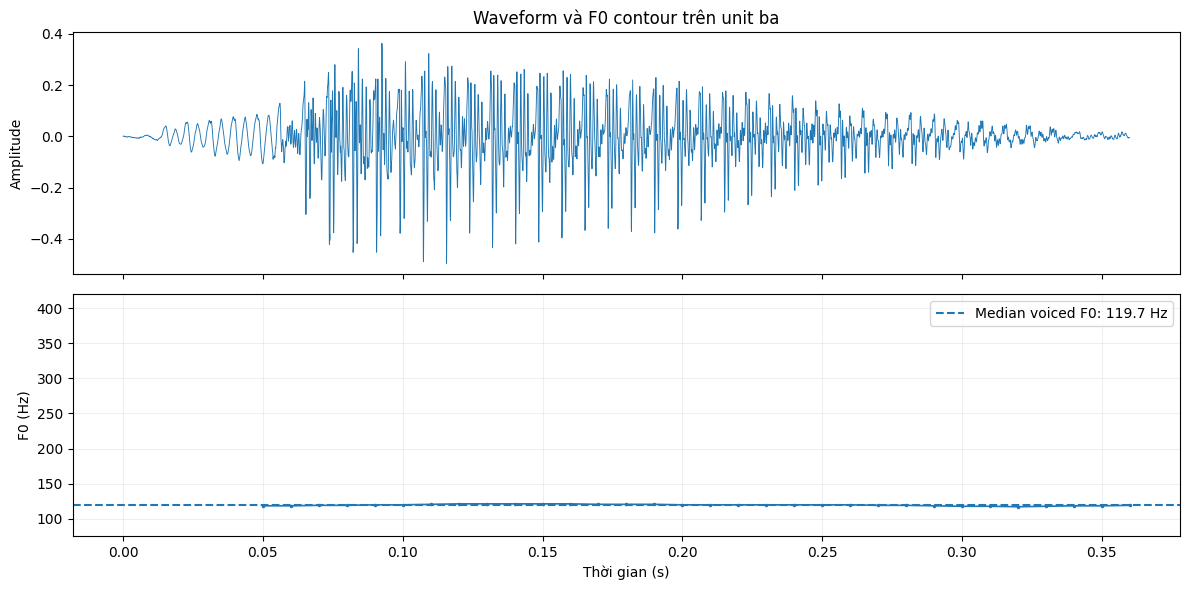

In [3]:
HOP = 160                         # 10 ms / frame
FMIN, FMAX = 75, 420              # miền F0 dự kiến (Hz)
f0, voiced_flag, voiced_prob = librosa.pyin(
    unit_trim, sr=SR, fmin=FMIN, fmax=FMAX, frame_length=1024, hop_length=HOP
)
t_f0 = librosa.frames_to_time(np.arange(len(f0)),sr=SR,hop_length=HOP)
voiced = np.isfinite(f0) & voiced_flag
n_voiced = int(voiced.sum())
if n_voiced == 0:
    raise RuntimeError('Không phát hiện frame hữu thanh trong ba_01.wav; hãy nghe lại từ ba hoặc chọn file hữu thanh rõ hơn.')
median_f0 = float(np.median(f0[voiced]))
print(f'F0 median từ pYIN = {median_f0:.2f} Hz | {n_voiced}/{len(f0)} frame hữu thanh')

fig,axs=plt.subplots(2,1,figsize=(12,6),sharex=True)
axs[0].plot(np.arange(len(unit_trim))/SR,unit_trim,lw=.65)
axs[0].set(ylabel='Amplitude',title='Waveform và F0 contour trên unit ba')
axs[1].plot(t_f0,f0,marker='.',ms=3,lw=1.2)
axs[1].axhline(median_f0,ls='--',label=f'Median voiced F0: {median_f0:.1f} Hz')
axs[1].set(xlabel='Thời gian (s)',ylabel='F0 (Hz)',ylim=(FMIN,FMAX))
axs[1].legend(); axs[1].grid(alpha=.2)
fig.tight_layout(); fig.savefig(FIG_DIR/'d_f0_contour.png',dpi=180); plt.show()

Frame index=9; F0 pYIN=119.74 Hz
Autocorrelation cho Np=134 samples → Fs/Np=119.40 Hz


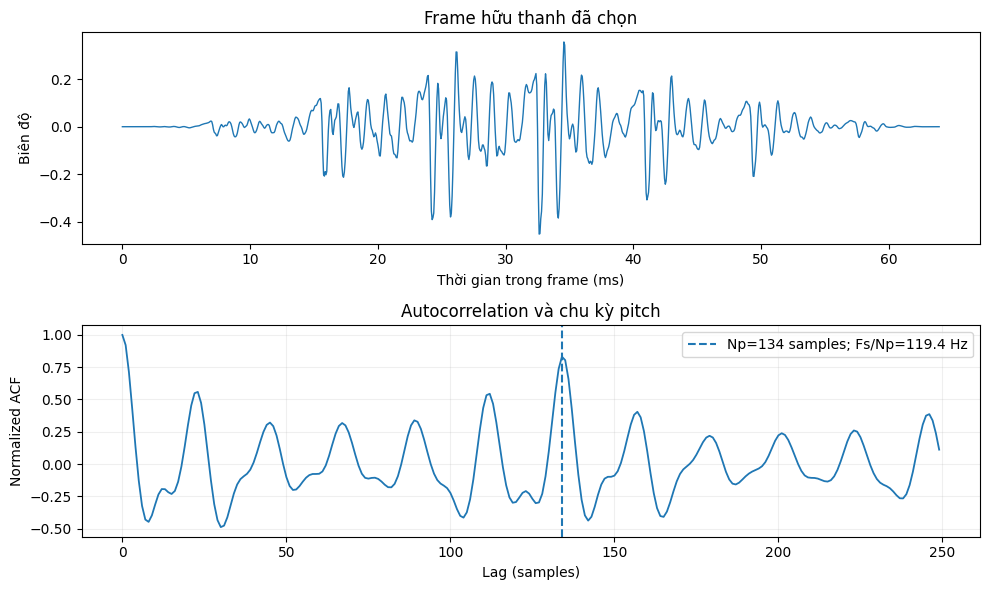

In [4]:
# Chọn một frame pYIN gần F0 median, lấy đoạn ~64 ms quanh tâm
candidates = np.flatnonzero(voiced)
frame_id = int(candidates[np.argmin(np.abs(f0[candidates]-median_f0))])
center = frame_id*HOP
N_FRAME=1024
left = max(0,min(center-N_FRAME//2,len(unit_trim)-N_FRAME))
frame = unit_trim[left:left+N_FRAME].astype('float64')
frame = (frame-np.mean(frame))*np.hanning(len(frame))
acf=correlate(frame,frame,mode='full',method='fft')[len(frame)-1:]
acf=acf/(acf[0]+1e-12)

# Khoanh vùng một chu kỳ dựa trên f0 đã đo để hạn chế lỗi double/half pitch
pred_period = SR/float(f0[frame_id])
lag_lo=max(int(SR/FMAX),int(pred_period*0.75))
lag_hi=min(int(SR/FMIN),int(pred_period*1.25))
if lag_hi <= lag_lo:
    raise RuntimeError('Không thể xác định vùng chu kỳ cần kiểm tra')
Np=int(lag_lo + np.argmax(acf[lag_lo:lag_hi+1]))
f0_from_period=SR/Np
print(f'Frame index={frame_id}; F0 pYIN={f0[frame_id]:.2f} Hz')
print(f'Autocorrelation cho Np={Np} samples → Fs/Np={f0_from_period:.2f} Hz')

fig,axs=plt.subplots(2,1,figsize=(10,6))
axs[0].plot(np.arange(len(frame))/SR*1000,frame,lw=1)
axs[0].set(xlabel='Thời gian trong frame (ms)',ylabel='Biên độ',title='Frame hữu thanh đã chọn')
axs[1].plot(np.arange(0,250),acf[:250],lw=1.3)
axs[1].axvline(Np,ls='--',label=f'Np={Np} samples; Fs/Np={f0_from_period:.1f} Hz')
axs[1].set(xlabel='Lag (samples)',ylabel='Normalized ACF',title='Autocorrelation và chu kỳ pitch')
axs[1].legend();axs[1].grid(alpha=.2)
fig.tight_layout();fig.savefig(FIG_DIR/'d_pitch_period_autocorrelation.png',dpi=180);plt.show()

pd.DataFrame([{'unit_source':unit_source,'sample_rate_hz':SR,'pYIN_median_f0_hz':median_f0,
               'pYIN_selected_frame_f0_hz':float(f0[frame_id]),'Np_samples':Np,
               'autocorrelation_f0_hz':f0_from_period,'num_voiced_frames':n_voiced}]).to_csv(
    OUT_DIR/'d_f0_measurements.csv',index=False,encoding='utf-8-sig')

## 3. Thí nghiệm thay duration/speed: 0.8×, 1.0×, 1.2×

Sử dụng `librosa.effects.time_stretch(..., rate=...)`: thay thời lượng nhưng **cố gắng giữ nguyên pitch**.

- `rate=0.8`: **chậm hơn**, độ dài kỳ vọng tăng lên khoảng $1/0.8=1.25$ lần.
- `rate=1.0`: tốc độ gốc.
- `rate=1.2`: **nhanh hơn**, thời lượng kỳ vọng còn khoảng $1/1.2\approx0.833$ lần.

Âm lượng và artefact có thể thay đổi do phase vocoder; nghe trực tiếp và không mặc định rằng 1.0× luôn tốt nhất về mọi tiêu chí.

In [5]:
def save_audio(path, x):
    y = np.asarray(x,dtype='float32')
    peak=float(np.max(np.abs(y))) if len(y) else 0.0
    if peak >= 0.999:
        print(f'CẢNH BÁO: {path.name} đạt peak {peak:.3f}, scale để tránh clipping')
        y=y*(0.98/peak)
    sf.write(path, y, SR, subtype='PCM_16')
    return y

speed_rates=[0.8,1.0,1.2]
speed_unit={}
speed_full={}
for rate in speed_rates:
    label=str(rate).replace('.','p')
    speed_unit[rate]=unit_trim.copy() if rate==1.0 else librosa.effects.time_stretch(unit_trim,rate=rate)
    y = best.copy() if rate==1.0 else librosa.effects.time_stretch(best,rate=rate)
    filename=OUT_DIR/f'd_speed_{label}x.wav'
    speed_full[rate]=save_audio(filename,y)
    print(f'Rate {rate:.1f}x: duration={len(y)/SR:.3f} s, ratio={len(y)/len(best):.3f} → {filename.name}')

for rate in speed_rates:
    print(f'Nghe speed {rate:.1f}x')
    display(Audio(data=speed_full[rate],rate=SR))

Rate 0.8x: duration=6.100 s, ratio=1.250 → d_speed_0p8x.wav
Rate 1.0x: duration=4.880 s, ratio=1.000 → d_speed_1p0x.wav
Rate 1.2x: duration=4.067 s, ratio=0.833 → d_speed_1p2x.wav
Nghe speed 0.8x


Nghe speed 1.0x


Nghe speed 1.2x


## 4. Thí nghiệm thay F0 / Pitch shift: −2, 0, +2 semitone

Quan hệ semitone và tỷ số tần số:

\[
r=2^{\Delta s/12},\qquad F_{0,\mathrm{new}}\approx r F_{0,\mathrm{old}}.
\]

`librosa.effects.pitch_shift(..., n_steps=...)` thay cao độ **cố gắng giữ thời lượng** và hạn chế đổi spectral envelope. Đây là phương pháp xử lý tín hiệu, không phải training TTS.

In [6]:
semitones=[-2,0,2]
pitch_unit={}
pitch_full={}
for step in semitones:
    pitch_unit[step]=unit_trim.copy() if step==0 else librosa.effects.pitch_shift(unit_trim,sr=SR,n_steps=step)
    y=best.copy() if step==0 else librosa.effects.pitch_shift(best,sr=SR,n_steps=step)
    suffix=('m'+str(abs(step))) if step<0 else ('p'+str(step))
    filename=OUT_DIR/f'd_pitch_{suffix}.wav'
    pitch_full[step]=save_audio(filename,y)
    print(f'Shift {step:+d}: theoretical F0 ratio={2**(step/12):.4f}; duration={len(y)/SR:.3f}s → {filename.name}')

for step in semitones:
    print(f'Nghe pitch shift {step:+d} semitone')
    display(Audio(data=pitch_full[step],rate=SR))

Shift -2: theoretical F0 ratio=0.8909; duration=4.880s → d_pitch_m2.wav
Shift +0: theoretical F0 ratio=1.0000; duration=4.880s → d_pitch_p0.wav
Shift +2: theoretical F0 ratio=1.1225; duration=4.880s → d_pitch_p2.wav
Nghe pitch shift -2 semitone


Nghe pitch shift +0 semitone


Nghe pitch shift +2 semitone


## 5. Thống kê thí nghiệm & spectrogram

Đo lại F0 **trên cùng một unit**, không đo F0 trung vị của cả câu chứa nhiều khoảng vô thanh. Với pitch-shift ±2, tỷ số dự kiến xấp xỉ $2^{\pm2/12}$; đo đạc có thể lệch do artefact thuật toán.

So sánh spectrogram cần giữ **chung dải màu (dB)**, cùng sample rate và cùng `nfft/hop` để tránh đánh giá sai do thay đổi thang hiển thị.

In [7]:
def median_voiced_f0(x):
    f,flags,_=librosa.pyin(x,sr=SR,fmin=FMIN,fmax=FMAX,frame_length=1024,hop_length=HOP)
    good = f[np.isfinite(f)&flags]
    return float(np.median(good)) if len(good) else np.nan

rows=[]
for rate in speed_rates:
    x=speed_unit[rate]; y=speed_full[rate]
    rows.append({'variant':'speed','setting':f'{rate:.1f}x','speed_rate':rate,'pitch_semitones':0,
        'full_duration_s':len(y)/SR,'duration_ratio_to_best':len(y)/len(best),
        'unit_f0_median_hz':median_voiced_f0(x),'expected_f0_ratio':1.0,
        'unit_rms':rms(x),'output_filename':f'd_speed_{str(rate).replace(".","p")}x.wav'})
for step in semitones:
    x=pitch_unit[step]; y=pitch_full[step]
    suffix=('m'+str(abs(step))) if step<0 else ('p'+str(step))
    rows.append({'variant':'pitch','setting':f'{step:+d} semitone','speed_rate':1.0,'pitch_semitones':step,
        'full_duration_s':len(y)/SR,'duration_ratio_to_best':len(y)/len(best),
        'unit_f0_median_hz':median_voiced_f0(x),'expected_f0_ratio':float(2**(step/12)),
        'unit_rms':rms(x),'output_filename':f'd_pitch_{suffix}.wav'})
experiment_df=pd.DataFrame(rows)
experiment_df['f0_ratio_measured']=experiment_df['unit_f0_median_hz']/median_f0
experiment_df.to_csv(OUT_DIR/'d_prosody_experiments.csv',index=False,encoding='utf-8-sig')
display(experiment_df.round(4))

,variant,setting,speed_rate,pitch_semitones,full_duration_s,duration_ratio_to_best,unit_f0_median_hz,expected_f0_ratio,unit_rms,output_filename,f0_ratio_measured
0,speed,0.8x,0.8,0,6.1000,1.2500,119.7448,1.0000,0.0745,d_speed_0p8x.wav,1.0000
1,speed,1.0x,1.0,0,4.8800,1.0000,119.7448,1.0000,0.0943,d_speed_1p0x.wav,1.0000
2,speed,1.2x,1.2,0,4.0667,0.8333,119.7448,1.0000,0.0866,d_speed_1p2x.wav,1.0000
3,pitch,-2 semitone,1.0,-2,4.8800,1.0000,106.6805,0.8909,0.0893,d_pitch_m2.wav,0.8909
4,pitch,+0 semitone,1.0,0,4.8800,1.0000,119.7448,1.0000,0.0943,d_pitch_p0.wav,1.0000
5,pitch,+2 semitone,1.0,2,4.8800,1.0000,134.4089,1.1225,0.0740,d_pitch_p2.wav,1.1225


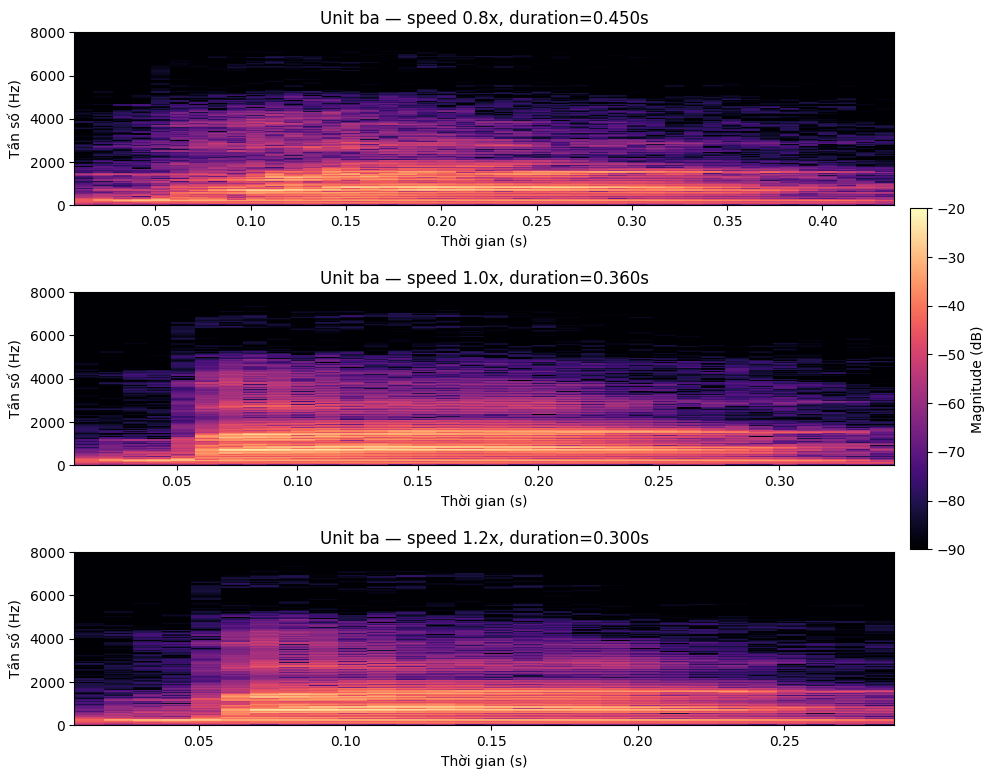

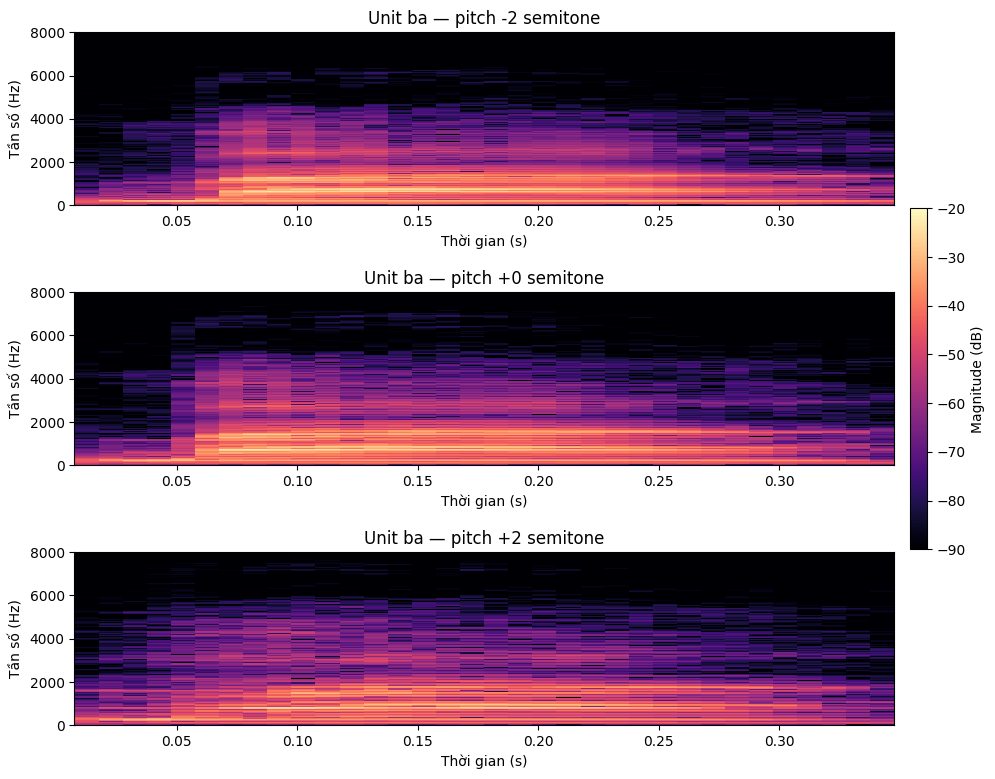

In [8]:
def spectrogram(ax,x,title,vmin=-90,vmax=-20):
    freqs,times,z=stft(x,fs=SR,window='hann',nperseg=400,noverlap=240,nfft=512,boundary=None,padded=False)
    db=20*np.log10(np.maximum(np.abs(z),1e-10))
    img=ax.pcolormesh(times,freqs,db,shading='auto',cmap='magma',vmin=vmin,vmax=vmax)
    ax.set(xlabel='Thời gian (s)',ylabel='Tần số (Hz)',ylim=(0,8000),title=title)
    return img

fig,axs=plt.subplots(3,1,figsize=(11,9))
for ax,r in zip(axs,speed_rates):
    img=spectrogram(ax,speed_unit[r],f'Unit ba — speed {r:.1f}x, duration={len(speed_unit[r])/SR:.3f}s')
fig.colorbar(img,ax=axs,label='Magnitude (dB)',fraction=0.02,pad=0.02)
fig.subplots_adjust(hspace=.5,right=.87)
fig.savefig(FIG_DIR/'d_duration_speed_spectrogram.png',dpi=165,bbox_inches='tight');plt.show()

fig,axs=plt.subplots(3,1,figsize=(11,9))
for ax,s in zip(axs,semitones):
    img=spectrogram(ax,pitch_unit[s],f'Unit ba — pitch {s:+d} semitone')
fig.colorbar(img,ax=axs,label='Magnitude (dB)',fraction=0.02,pad=0.02)
fig.subplots_adjust(hspace=.5,right=.87)
fig.savefig(FIG_DIR/'d_pitch_shift_spectrogram.png',dpi=165,bbox_inches='tight');plt.show()

## 6. Source–filter: mô phỏng tách nguồn kích thích và bộ lọc

Mô hình của Lab:

\[
X(z)=E(z)H(z).
\]

- $E(z)$: nguồn kích thích (ở đây là chuỗi xung đều cho voiced).
- $H(z)$: bộ lọc cộng hưởng **giữ cố định** để minh họa formant/spectral envelope.
- Tăng F0 làm các vạch harmonic xa nhau; **không bắt buộc** dời các tần số cộng hưởng của bộ lọc.

**Giới hạn:** Đây chỉ là demo signal-processing của source–filter; không phải bộ tổng hợp tiếng Việt hoàn chỉnh, và **không phải HMM**.

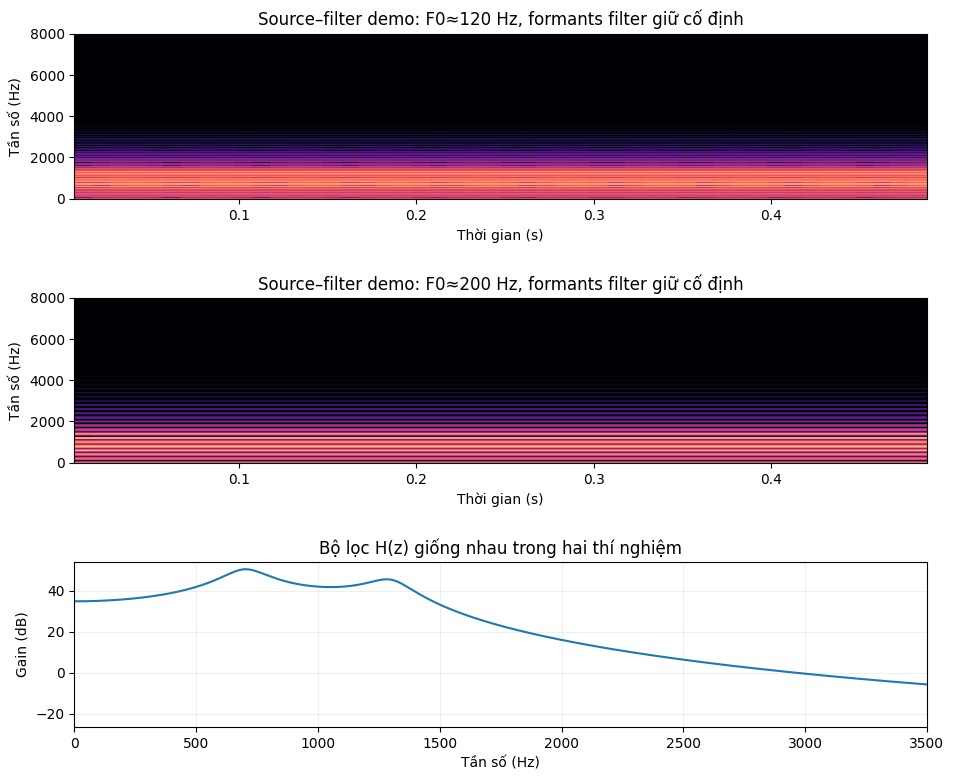

Lưu ý: minh họa trên chỉ chứng minh độc lập source–filter; không đánh giá naturalness.


In [9]:
from scipy.signal import convolve

def resonator_coeff(freq_hz,radius=.968):
    omega=2*np.pi*freq_hz/SR
    return np.array([1.0,-2*radius*np.cos(omega),radius**2])

A=np.convolve(resonator_coeff(700),resonator_coeff(1300))
B=np.array([1.0])
source_filter_samples={}
for ff in [120,200]:
    n=int(.5*SR)
    excite=np.zeros(n)
    pitch_period=int(round(SR/ff))
    excite[::pitch_period]=1.0
    synth=lfilter(B,A,excite).astype('float64')
    synth=.25*synth/(np.max(np.abs(synth))+1e-12)
    source_filter_samples[ff]=synth

fig,axs=plt.subplots(3,1,figsize=(11,9))
for ax,ff in zip(axs[:2],[120,200]):
    img=spectrogram(ax,source_filter_samples[ff],f'Source–filter demo: F0≈{ff} Hz, formants filter giữ cố định')
w,h=freqz(B,A,worN=2048,fs=SR)
axs[2].plot(w,20*np.log10(np.maximum(np.abs(h),1e-9)))
axs[2].set(xlim=(0,3500),xlabel='Tần số (Hz)',ylabel='Gain (dB)',title='Bộ lọc H(z) giống nhau trong hai thí nghiệm')
axs[2].grid(alpha=.2)
fig.subplots_adjust(hspace=.6)
fig.savefig(FIG_DIR/'d_source_filter_demo.png',dpi=165,bbox_inches='tight');plt.show()
print('Lưu ý: minh họa trên chỉ chứng minh độc lập source–filter; không đánh giá naturalness.')

## 7. Phiếu nghe & bảng kiểm tra bài nộp

**Việc người thực hành tự đánh giá:** nghe các bản WAV và ghi mức **intelligibility, naturalness, artifact/buzziness** (1–5), ghi chú những từ nghe khó. Đoạn code không được tự điền điểm MOS thay người nghe.

In [10]:
ratings_path=OUT_DIR/'d_listening_template.csv'
if not ratings_path.exists():
    pd.DataFrame([{'variant':r['variant'],'setting':r['setting'],'wav':r['output_filename'],
                   'intelligibility_1_to_5':'','naturalness_1_to_5':'',
                   'buzziness_1_to_5':'','notes':''} for r in rows]).to_csv(
        ratings_path,index=False,encoding='utf-8-sig')
    print('Đã tạo phiếu nghe:',ratings_path)
else:
    print('Giữ nguyên phiếu nghe đã điền:',ratings_path)

required=[OUT_DIR/'d_f0_measurements.csv',OUT_DIR/'d_prosody_experiments.csv',
          FIG_DIR/'d_f0_contour.png',FIG_DIR/'d_pitch_period_autocorrelation.png',
          FIG_DIR/'d_duration_speed_spectrogram.png',FIG_DIR/'d_pitch_shift_spectrogram.png',
          FIG_DIR/'d_source_filter_demo.png',ratings_path]
print('\n=== KẾT QUẢ BƯỚC D ===')
for p in required:
    print('OK' if p.exists() else 'THIẾU',p.relative_to(ROOT))
print('\n=> Gửi d_prosody_experiments.csv, d_f0_measurements.csv, 3 biểu đồ F0/speed/pitch và ghi chú nghe thử.')

Đã tạo phiếu nghe: C:\xulyamthanh\lab04_2351260688_NguyenNgocTien\audio_output\d_listening_template.csv

=== KẾT QUẢ BƯỚC D ===
OK audio_output\d_f0_measurements.csv
OK audio_output\d_prosody_experiments.csv
OK figures\d_f0_contour.png
OK figures\d_pitch_period_autocorrelation.png
OK figures\d_duration_speed_spectrogram.png
OK figures\d_pitch_shift_spectrogram.png
OK figures\d_source_filter_demo.png
OK audio_output\d_listening_template.csv

=> Gửi d_prosody_experiments.csv, d_f0_measurements.csv, 3 biểu đồ F0/speed/pitch và ghi chú nghe thử.


## 8. Gợi ý viết báo cáo phần D

1. **Phương pháp:** Dùng file `ba_01.wav` (hoặc trích `ba` từ baseline) và `best_concat.wav`. Giữ $F_s=16$ kHz. Dùng pYIN để xác định F0 ở frame hữu thanh, ACF để tính $N_p$ và $F_s/N_p$.
2. **Thí nghiệm speed:** 0.8×, 1.0×, 1.2× với time-stretch. Mô tả thời lượng thực tế, biến dạng nghe được, ảnh hưởng tới độ rõ.
3. **Thí nghiệm pitch:** −2/0/+2 semitone. So sánh tỷ số kỳ vọng $2^{\Delta s/12}$ và F0 đo được, ghi chú buzziness/artefact. Không khẳng định thuật toán giữ nguyên formant *hoàn toàn*.
4. **Source–filter:** Trình bày $X(z)=E(z)H(z)$; khi đổi chu kỳ kích thích, khoảng cách harmonic đổi nhưng đáp ứng cộng hưởng của bộ lọc giữ nguyên trong mô phỏng.
5. **Giới hạn:** Chất lượng âm thanh phụ thuộc unit và thuật toán time-stretch/pitch-shift; điểm nghe là đánh giá chủ quan và cần thu thật, không tự sinh từ chỉ số kỹ thuật.

**Kết quả cần lưu:** 6 WAV, `d_f0_measurements.csv`, `d_prosody_experiments.csv`, 5–6 biểu đồ và ghi chú nghe thử.

**Tiếp theo:** Phần E – HMM-based synthesis (theo yêu cầu lab: state sequence, F0 contour và một spectral/formant trajectory). Không lấy biểu đồ source–filter của phần D để thay thế phần E.